In [1]:
# Load data 

import glob, os
import numpy as np
import pandas as pd
from scipy.io import loadmat

DATA_DIR = "../data/M0-anonyme"  

files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.mat"), recursive=True))
print(len(files), "files found")

def load_mat(path):
    try:
        return loadmat(path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:  # MATLAB v7.3 (HDF5)
        import h5py
        out = {}
        with h5py.File(path, "r") as f:
            for k in f.keys():
                try: out[k] = np.array(f[k]).squeeze()
                except Exception: pass
        return out

# load everything into a dict: {filename: {var: value}}
data = {}
for p in files:
    try:
        d = load_mat(p)
        data[os.path.basename(p)] = {k: v for k, v in d.items() if not k.startswith("__")}
    except Exception as e:
        print("LOAD ERROR", os.path.basename(p), "->", e)

# quick look at the first file
file1 = next(iter(data))
print("\nFirst file:", file1)
for k, v in data[file1].items():
    a = np.asarray(v) if not hasattr(v, "_fieldnames") else None
    print(f"  {k:20s} {type(v).__name__:12s} shape={getattr(a, 'shape', 'struct')} dtype={getattr(a, 'dtype', '')}")

294 files found

First file: 001-GAYlo-M0.mat
  ECG                  ndarray      shape=(6746000,) dtype=float64
  Fe                   int          shape=() dtype=int64
  RR                   ndarray      shape=(77706,) dtype=uint16
  RRcorr               ndarray      shape=(77708,) dtype=float64
  t                    ndarray      shape=(77706,) dtype=float64
  tcorr                ndarray      shape=(77708,) dtype=float64


In [2]:
d = data[file1]
Fe = int(d["Fe"])
ecg, rr, rrc, t, tc = d["ECG"], d["RR"].astype(float), d["RRcorr"], d["t"], d["tcorr"]

print("Fe =", Fe, "Hz")
print(f"ECG duration: {len(ecg)/Fe/60:.1f} min = {len(ecg)/Fe/60/60:.2f} hours")
print(f"RR   : n={len(rr)}, min={rr.min():.0f}, median={np.median(rr):.0f}, max={rr.max():.0f}")
print(f"BPM  : min={60000/rr.max():.1f}, median={60000/np.median(rr):.1f}, max={60000/rr.min():.1f}\n")
print(f"RRc  : n={len(rrc)}, min={rrc.min():.3f}, median={np.median(rrc):.3f}, max={rrc.max():.3f}")
print(f"BPMc : min={60000/rrc.max():.1f}, median={60000/np.median(rrc):.1f}, max={60000/rrc.min():.1f}\n")
print(f"t    : start={t[0]:.2f}, end={t[-1]:.2f}")
print(f"tc   :  start={tc[0]:.2f}, end={tc[-1]:.2f}\n")

# do t and RR agree?  (t diff should match RR)
print("median |diff(t) - RR/1000|:", np.median(np.abs(np.diff(t) - rr[1:]/1000)))
print("median |diff(tcorr) - RRcorr[1:]|:", np.median(np.abs(np.diff(tc) - rrc[1:])))


Fe = 200 Hz
ECG duration: 562.2 min = 9.37 hours
RR   : n=77706, min=178, median=446, max=1408
BPM  : min=42.6, median=134.5, max=337.1

RRc  : n=77708, min=178.000, median=446.000, max=1044.000
BPMc : min=57.5, median=134.5, max=337.1

t    : start=364.00, end=33697816.00
tc   :  start=364.00, end=33697816.00

median |diff(t) - RR/1000|: 445.553
median |diff(tcorr) - RRcorr[1:]|: 7.0


# 📝

- We still have suspicious values (337bpm)
- Tc and RRc may not be aligned

In [3]:
import h5py
from scipy.io import loadmat, whosmat
import gc

SMALL = ["Fe", "RR", "RRcorr", "t", "tcorr"]

def ecg_len(path):
    """ECG length without loading it."""
    try:
        for n, shp, _ in whosmat(path):
            if n == "ECG": return int(np.prod(shp))
    except NotImplementedError:                       
        with h5py.File(path, "r") as f:
            return int(np.prod(f["ECG"].shape))

def load_small(path):
    try:
        return loadmat(path, variable_names=SMALL, squeeze_me=True)
    except NotImplementedError:
        with h5py.File(path, "r") as f:
            return {k: np.array(f[k]).squeeze() for k in SMALL if k in f}

rows = []
for p in files:
    r = dict(file=os.path.basename(p))
    try:
        d = load_small(p)
        Fe  = int(d["Fe"]); n_ecg = ecg_len(p)
        rr, rrc = np.asarray(d["RR"], float), np.asarray(d["RRcorr"], float)
        tc = np.asarray(d["tcorr"], float)
        r.update(Fe=Fe, ecg_h=n_ecg / Fe / 3600, t_end_h=tc[-1] / 3.6e6,
                 n_rr=len(rr), n_rrc=len(rrc), n_added=len(rrc) - len(rr),
                 rr_min=rr.min(), rr_max=rr.max(),
                 rrc_min=rrc.min(), rrc_med=np.median(rrc), rrc_max=rrc.max(),
                 mean_bpm=60000 / rrc.mean(),
                 pct_rrc_lt300=(rrc < 300).mean() * 100,
                 pct_rrc_gt1000=(rrc > 1000).mean() * 100)
    except Exception as e:
        r["error"] = str(e)[:80]
    rows.append(r)
    del d; gc.collect()

eda = pd.DataFrame(rows).set_index("file")
print(len(eda), "files | errors:", eda["error"].notna().sum() if "error" in eda else 0)
print("Fe values:", eda["Fe"].value_counts().to_dict())
display(eda.describe().T.round(2))

294 files | errors: 0
Fe values: {200: 294}


,count,mean,std,min,25%,50%,75%,max
Fe,294.0,200.00,0.00,200.00,200.00,200.00,200.00,200.00
ecg_h,294.0,19.65,2.72,2.95,18.46,19.76,21.33,23.89
t_end_h,294.0,21.82,5.96,2.94,18.54,20.19,22.24,40.57
n_rr,294.0,148771.47,25102.71,14212.00,136816.75,150498.50,163165.00,213766.00
n_rrc,294.0,147814.76,26227.76,10847.00,136234.75,149770.50,162949.50,213630.00
n_added,294.0,-956.70,3341.17,-26199.00,-704.75,-68.50,85.25,9584.00
rr_min,294.0,34.26,30.85,11.00,15.00,25.00,41.00,243.00
rr_max,294.0,19008.59,6767.06,1408.00,14288.25,21439.50,23581.25,34918.00
rrc_min,294.0,38.88,57.05,0.00,2.37,10.86,50.65,245.00
rrc_med,294.0,471.94,50.43,354.00,445.00,467.50,488.00,838.00


---

In [4]:

import matplotlib.pyplot as plt

eda["t_ratio"] = eda["t_end_h"] / eda["ecg_h"]
print("t_end / ecg duration:"); display(eda["t_ratio"].describe().round(3))
print("ratio > 1.05:", (eda.t_ratio > 1.05).sum(), "| ratio < 0.95:", (eda.t_ratio < 0.95).sum())

cols = ["ecg_h", "t_end_h", "t_ratio", "n_rr", "n_rrc", "rrc_min", "rrc_med", "rrc_max", "pct_rrc_lt300", "pct_rrc_gt1000"]
print("Worst time mismatch:");     display(eda.sort_values("t_ratio", ascending=False).head(8)[cols].round(2))


t_end / ecg duration:


count    294.000
mean       1.108
std        0.258
min        0.997
25%        0.999
50%        1.000
75%        1.000
max        2.610
Name: t_ratio, dtype: float64

ratio > 1.05: 48 | ratio < 0.95: 0
Worst time mismatch:


,ecg_h,t_end_h,t_ratio,n_rr,n_rrc,rrc_min,rrc_med,rrc_max,pct_rrc_lt300,pct_rrc_gt1000
file,,,,,,,,,,
096-BOYle-M0.mat,12.77,33.33,2.61,103411,103422,168.20,449.0,1118.00,0.06,0.00
072-GALch-M0.mat,17.06,33.17,1.94,148948,148473,26.52,408.0,11371.68,0.54,0.16
086-MONti-M0.mat,17.68,33.69,1.91,145876,146747,1.89,425.0,8009.75,1.51,0.21
081-YAHly-M0.mat,17.60,33.13,1.88,132049,131999,82.89,476.0,7470.67,0.41,0.08
062-DUFle-M0.mat,18.45,34.16,1.85,136414,135619,2.83,455.0,10556.96,0.29,2.19
066-SAVar-M0.mat,17.72,32.74,1.85,133345,133352,174.00,486.0,1664.00,0.07,0.01
082-PATlu-M0.mat,18.14,33.33,1.84,145237,145920,2.22,448.0,12637.87,0.29,0.30
061-AISil-M0.mat,18.37,33.49,1.82,136543,136393,68.66,487.0,10086.58,0.45,0.17


In [5]:
cols = ["ecg_h", "t_end_h", "t_ratio", "n_rr", "n_rrc", "rrc_min", "rrc_med", "rrc_max", "pct_rrc_lt300", "pct_rrc_gt1000"]
bad = eda[eda.t_ratio > 1.05].sort_values("t_ratio", ascending=False)

print("Worst time mismatch (t_ratio > 1.05):", len(bad), "of", len(eda), "children")
display(bad[cols].round(2))

Worst time mismatch (t_ratio > 1.05): 48 of 294 children


,ecg_h,t_end_h,t_ratio,n_rr,n_rrc,rrc_min,rrc_med,rrc_max,pct_rrc_lt300,pct_rrc_gt1000
file,,,,,,,,,,
096-BOYle-M0.mat,12.77,33.33,2.61,103411,103422,168.20,449.0,1118.00,0.06,0.00
072-GALch-M0.mat,17.06,33.17,1.94,148948,148473,26.52,408.0,11371.68,0.54,0.16
086-MONti-M0.mat,17.68,33.69,1.91,145876,146747,1.89,425.0,8009.75,1.51,0.21
081-YAHly-M0.mat,17.60,33.13,1.88,132049,131999,82.89,476.0,7470.67,0.41,0.08
062-DUFle-M0.mat,18.45,34.16,1.85,136414,135619,2.83,455.0,10556.96,0.29,2.19
066-SAVar-M0.mat,17.72,32.74,1.85,133345,133352,174.00,486.0,1664.00,0.07,0.01
082-PATlu-M0.mat,18.14,33.33,1.84,145237,145920,2.22,448.0,12637.87,0.29,0.30
061-AISil-M0.mat,18.37,33.49,1.82,136543,136393,68.66,487.0,10086.58,0.45,0.17
091-TALsa-M0.mat,18.52,33.64,1.82,135001,135141,115.90,496.0,8519.76,0.10,0.05


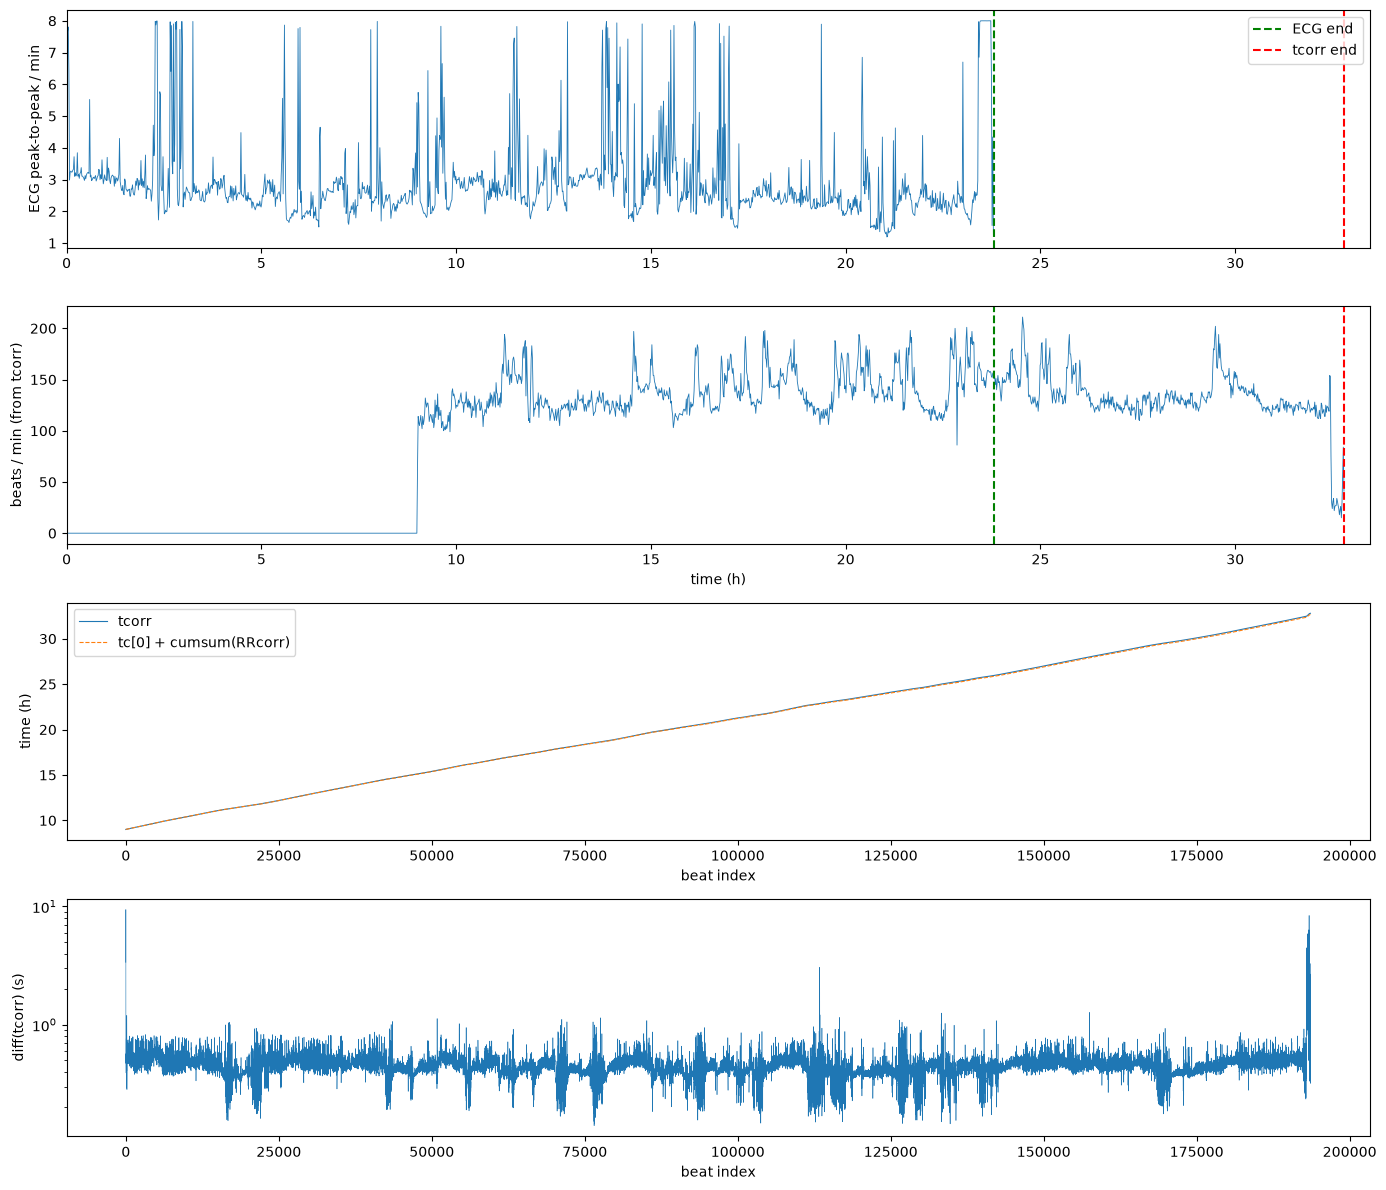

1783

In [6]:
NAME =  "065-THIhe-M0.mat"  #"099-BOUma-M0.mat" #"076-COUjo-M0.mat" #"096-BOYle-M0.mat"   

p = next(f for f in files if os.path.basename(f) == NAME)
d = loadmat(p, squeeze_me=True)
ecg, Fe = np.asarray(d["ECG"], float), int(d["Fe"])
rrc, tc = np.asarray(d["RRcorr"], float), np.asarray(d["tcorr"], float)

H = 3.6e6           # ms -> hours  
                      
# ECG amplitude per minute
n = Fe * 60
m = len(ecg) // n
amp = np.ptp(ecg[:m * n].reshape(m, n), axis=1)
x_ecg = (np.arange(m) + .5) / 60            # hours

# beats per minute from tcorr
bins = np.arange(0, max(tc[-1] / 6e4, m) + 1)
bpm_t = np.histogram(tc / 6e4, bins=bins)[0]
x_b = (bins[:-1] + .5) / 60

fig, ax = plt.subplots(4, 1, figsize=(14, 12))
ax[0].plot(x_ecg, amp, lw=.6); ax[0].set_ylabel("ECG peak-to-peak / min")
ax[1].plot(x_b, bpm_t, lw=.6);  ax[1].set_ylabel("beats / min (from tcorr)")
for a in ax[:2]:
    a.axvline(len(ecg) / Fe / 3600, color="g", ls="--", label="ECG end")
    a.axvline(tc[-1] / H, color="r", ls="--", label="tcorr end"); a.set_xlim(0, tc[-1] / H * 1.02)
ax[0].legend(); ax[1].set_xlabel("time (h)")

ax[2].plot(tc / H, lw=.8, label="tcorr")
ax[2].plot((tc[0] + np.cumsum(rrc)) / H, "--", lw=.8, label="tc[0] + cumsum(RRcorr)")
ax[2].set_ylabel("time (h)"); ax[2].set_xlabel("beat index"); ax[2].legend()
ax[3].semilogy(np.diff(tc) / 1e3, lw=.4); ax[3].set_ylabel("diff(tcorr) (s)"); ax[3].set_xlabel("beat index")
plt.tight_layout(); plt.show()

del d, ecg; gc.collect()

In [7]:
start = {}
for p in files:
    d = loadmat(p, variable_names=["tcorr"], squeeze_me=True)
    start[os.path.basename(p)] = np.atleast_1d(d["tcorr"])[0] / 3.6e6     # hours
    del d
eda["start_h"] = pd.Series(start)
eda["dur_ratio"] = (eda.t_end_h - eda.start_h) / eda.ecg_h               # ~1 if tcorr is just offset

print("starting at ~0 (<0.01 h):", (eda.start_h < 0.01).sum(), "| clock-like (>=1 h):", (eda.start_h >= 1).sum(), "| of", len(eda))
print("dur_ratio  min/median/max:", eda.dur_ratio.agg(["min", "median", "max"]).round(3).tolist())

starting at ~0 (<0.01 h): 243 | clock-like (>=1 h): 48 | of 294
dur_ratio  min/median/max: [0.997, 0.999, 1.0]


➡️ t_ratio is just caused by an offset and it is not a real time

---

In [10]:
WIN_H  = 2.95
SEG_N  = 200 * 30                         # 6000 samples per 30 s segment
SEGS_PER_WIN = int(WIN_H * 3600 / 30)     # 342 segments per window
WIN_N  = SEGS_PER_WIN * SEG_N             # samples per window

def ecg_quality(path):
    d = loadmat(path, variable_names=["ECG"], squeeze_me=True)
    x = np.asarray(d["ECG"], np.float32).ravel(); del d
    n_win = len(x) // WIN_N
    s = x[:n_win * WIN_N].reshape(n_win * SEGS_PER_WIN, SEG_N)       # every 30 s segment inside full windows
    sd  = np.nanstd(s, axis=1)
    ptp = np.nanmax(s, axis=1) - np.nanmin(s, axis=1)
    flat = (np.abs(np.diff(s, axis=1)) < 1e-9).mean(axis=1)
    out = dict(n_win=n_win,
               leftover_min=(len(x) - n_win * WIN_N) / 200 / 60,       # ECG not used (end of recording)
               pct_nan_seg=np.isnan(s).any(axis=1).mean() * 100,
               pct_flat_seg=(flat > 0.5).mean() * 100,
               pct_spike_seg=(ptp > 5 * np.median(ptp)).mean() * 100,
               sd_med=np.median(sd), ptp_med=np.median(ptp))
    del x, s; gc.collect()
    return out

qdf = pd.DataFrame({os.path.basename(p): ecg_quality(p) for p in files}).T.astype(float)
eda = eda.drop(columns=[c for c in qdf.columns if c in eda.columns]).join(qdf)   # avoids duplicate-column errors
display(eda[["n_win", "leftover_min", "pct_nan_seg", "pct_flat_seg", "pct_spike_seg", "sd_med", "ptp_med"]].describe().T.round(2))
print("windows per child:", eda.n_win.astype(int).value_counts().sort_index().to_dict(), "| total windows:", int(eda.n_win.sum()))

,count,mean,std,min,25%,50%,75%,max
n_win,294.0,6.20,0.91,1.00,6.00,6.00,7.00,8.00
leftover_min,294.0,81.30,51.15,0.00,36.38,79.08,123.00,176.00
pct_nan_seg,294.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
pct_flat_seg,294.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
pct_spike_seg,294.0,0.62,2.41,0.00,0.00,0.00,0.00,31.07
sd_med,294.0,0.28,0.22,0.05,0.19,0.24,0.30,2.26
ptp_med,294.0,2.59,1.25,0.61,1.86,2.35,2.95,8.00


windows per child: {1: 3, 2: 1, 3: 1, 4: 4, 5: 21, 6: 158, 7: 102, 8: 4} | total windows: 1823


In [11]:
WIN_H = 2.35
WIN_N = int(WIN_H * 3600 * 200)                      # samples per window

rows = []
for p in files:
    d = loadmat(p, variable_names=["ECG"], squeeze_me=True)
    x = np.asarray(d["ECG"], np.float32).ravel(); del d
    for w in range(len(x) // WIN_N):
        s = x[w * WIN_N:(w + 1) * WIN_N]
        p1, p99 = np.nanpercentile(s, [1, 99])
        sd = np.nanstd(s)
        rows.append(dict(file=os.path.basename(p), win=w,
                         pct_nan=np.isnan(s).mean() * 100,
                         pct_flat=(np.diff(s) == 0).mean() * 100,      # repeated identical samples
                         sd=sd,
                         rng_1_99=p99 - p1,                            # robust amplitude range
                         peak_ratio=np.nanmax(np.abs(s - np.nanmedian(s))) / sd))   # high = spikes / outliers
    del x; gc.collect()

wq = pd.DataFrame(rows)
display(wq.drop(columns=["win"]).describe().T.round(3))
print("windows:", len(wq), "| children:", wq.file.nunique())

,count,mean,std,min,25%,50%,75%,max
pct_nan,2306.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
pct_flat,2306.0,0.325,0.112,0.002,0.258,0.321,0.386,1.461
sd,2306.0,0.383,0.284,0.012,0.237,0.310,0.421,2.680
rng_1_99,2306.0,2.403,1.509,0.014,1.468,1.983,2.726,7.923
peak_ratio,2306.0,12.865,8.872,1.495,8.959,12.165,15.626,323.360


windows: 2306 | children: 294
